# Applied Artificial Intelligence — Coursework 2 of 2

## Cross-Domain Sentiment Classification

Dataset: Johns Hopkins Multi-Domain Sentiment Dataset, version 2.0. The task trains on Books and evaluates on DVD, Electronics and Kitchen. It compares exactly two traditional models (Logistic Regression and Linear SVM) with two deep models (DNN and Residual MLP), each in baseline and refined forms.

The official processed ACL archive is downloaded from the JHU source. Raw data are not committed to the repository.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from assignment1.data import load_multidomain_dataset, dataset_summary
from assignment1.experiment import run_experiment
DATA_DIR = ROOT / 'data' / 'raw' / 'processed_acl'
RESULTS_DIR = ROOT / 'results'
SEED = 42

## 1. Dataset download and inspection

The official version 2.0 page provides a balanced binary archive in the processed ACL format. Each record stores word-feature counts followed by a sentiment label.

In [2]:
expected = ('positive.review', 'negative.review', 'processed.review.balanced', 'processed.review')
has_labelled_files = DATA_DIR.exists() and any(any(DATA_DIR.rglob(name)) for name in expected)
if not has_labelled_files:
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'download_dataset.py'), '--variant', 'processed_acl'], check=True)
else:
    print('An extracted labelled dataset folder already exists.')


Dataset extracted to: /home/runner/work/shamim-vai-project/shamim-vai-project/assignment -1/data/raw/processed_acl


,domain,documents,positive,negative,unique_features
0,books,2000,1000,1000,195876
1,dvd,2000,1000,1000,188768
2,electronics,2000,1000,1000,111395
3,kitchen,2000,1000,1000,93468


## 2. Data analysis

Each selected domain contains 1,000 positive and 1,000 negative reviews. All 8,000 available reviews are retained; the code cap is 1,000 per class, so no additional down-sampling occurs. Books is split into 1,280 training, 320 validation and 400 test reviews. The other three domains are reserved for cross-domain testing. No resampling is needed because the selected archive is balanced.

The parser excludes records without usable features or a valid binary label rather than imputing them. An absent feature in a sparse vector represents zero.

In [3]:
sample_counts = full_summary[['domain', 'positive', 'negative', 'documents']].copy()
display(sample_counts)
plot_summary = full_summary.copy()
plot_summary['domain'] = plot_summary['domain'].map({'books':'Books', 'dvd':'DVD', 'electronics':'Electronics', 'kitchen':'Kitchen'})
ax = plot_summary.set_index('domain')[['positive', 'negative']].plot(kind='bar', figsize=(8,4))
ax.set_title('Balanced review counts by product domain')
ax.set_xlabel('Domain'); ax.set_ylabel('Reviews'); ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()

,domain,positive,negative,documents
0,books,1000,1000,2000
1,dvd,1000,1000,2000
2,electronics,1000,1000,2000
3,kitchen,1000,1000,2000


## 3. Model training and refinement

Traditional models: Logistic Regression and Linear SVM. Deep models: DNN and Residual MLP. Traditional refinements tune regularisation on validation F1. Neural refinements change the hidden architecture and regularisation, then use early stopping.

In [4]:
metrics = run_experiment(
    data_dir=DATA_DIR,
    output_dir=RESULTS_DIR,
    source_domain='books',
    target_domains=['dvd', 'electronics', 'kitchen'],
    max_per_class=1000,
    max_features=5000,
    seed=SEED,
)
display(metrics.sort_values(['evaluation', 'model', 'stage']))


,model,stage,evaluation,n_test,validation_f1,accuracy,precision,recall,f1,roc_auc
9,Constant-negative baseline,reference,cross_domain:dvd,2000,NaN,0.5000,0.000000,0.000,0.000000,NaN
14,Deep Neural Network,baseline,cross_domain:dvd,2000,0.803922,0.7930,0.819869,0.751,0.783925,0.884115
15,Deep Neural Network,refined,cross_domain:dvd,2000,0.845238,0.7995,0.775529,0.843,0.807858,0.886894
12,Linear SVM,baseline,cross_domain:dvd,2000,0.797386,0.7935,0.823594,0.747,0.783429,0.882367
13,Linear SVM,refined,cross_domain:dvd,2000,0.831025,0.7415,0.680358,0.911,0.778965,0.872632
10,Logistic Regression,baseline,cross_domain:dvd,2000,0.773333,0.7865,0.834306,0.715,0.770059,0.870630
11,Logistic Regression,refined,cross_domain:dvd,2000,0.826816,0.7680,0.711356,0.902,0.795414,0.882419
16,Residual MLP,baseline,cross_domain:dvd,2000,0.809211,0.7950,0.832957,0.738,0.782609,0.879964
17,Residual MLP,refined,cross_domain:dvd,2000,0.821229,0.7650,0.718647,0.871,0.787523,0.868665
18,Constant-negative baseline,reference,cross_domain:electronics,2000,NaN,0.5000,0.000000,0.000,0.000000,NaN


## 4. Results and evaluation

The unified results table reports validation F1, accuracy, precision, recall, F1-score and ROC-AUC for the reference baseline and all baseline/refined model stages on the Books test set and three target domains. The same table is written to `results/metrics_summary.csv` and inserted into the LaTeX report.

In [5]:
refinement = pd.read_csv(RESULTS_DIR / 'refinement_comparison.csv')
display(refinement)
print('Unified model evaluation table:')
display(pd.read_csv(RESULTS_DIR / 'metrics_summary.csv'))

,model,stage,validation_f1,setting
0,Logistic Regression,baseline,0.773333,C=1.0; decision_threshold=0.50000
1,Logistic Regression,refined,0.826816,validation-selected C=10.0; decision_threshold...
2,Linear SVM,baseline,0.797386,C=1.0; decision_threshold=0.00000
3,Linear SVM,refined,0.831025,validation-selected C=10.0; decision_threshold...
4,Deep Neural Network,baseline,0.803922,"{""batch_size"": 64, ""best_epoch"": 10, ""dropout""..."
5,Deep Neural Network,refined,0.845238,"{""batch_size"": 64, ""best_epoch"": 7, ""dropout"":..."
6,Residual MLP,baseline,0.809211,"{""batch_size"": 64, ""best_epoch"": 2, ""dropout"":..."
7,Residual MLP,refined,0.821229,"{""batch_size"": 64, ""best_epoch"": 1, ""dropout"":..."


Unified model evaluation table:


,model,stage,evaluation,n_test,validation_f1,accuracy,precision,recall,f1,roc_auc
0,Constant-negative baseline,reference,in_domain,400,NaN,0.5000,0.000000,0.000,0.000000,NaN
1,Logistic Regression,baseline,in_domain,400,0.773333,0.8400,0.877778,0.790,0.831579,0.924375
2,Logistic Regression,refined,in_domain,400,0.826816,0.8150,0.754032,0.935,0.834821,0.933550
3,Linear SVM,baseline,in_domain,400,0.797386,0.8625,0.883598,0.835,0.858612,0.934600
4,Linear SVM,refined,in_domain,400,0.831025,0.8075,0.739300,0.950,0.831510,0.926375
5,Deep Neural Network,baseline,in_domain,400,0.803922,0.8650,0.880208,0.845,0.862245,0.935650
6,Deep Neural Network,refined,in_domain,400,0.845238,0.8600,0.827273,0.910,0.866667,0.935925
7,Residual MLP,baseline,in_domain,400,0.809211,0.8600,0.882979,0.830,0.855670,0.926825
8,Residual MLP,refined,in_domain,400,0.821229,0.8250,0.762097,0.945,0.843750,0.924775
9,Constant-negative baseline,reference,cross_domain:dvd,2000,NaN,0.5000,0.000000,0.000,0.000000,NaN


## 5. Visualisations

Logistic Regression estimates a positive-class probability using the sigmoid function:
$$P(y=1|x)=\\frac{1}{1+e^{-(w^Tx+b)}}$$
The F1-score is the harmonic mean of precision and recall:
$$F1=2\\frac{Precision\\times Recall}{Precision+Recall}$$

domain_class_balance.png


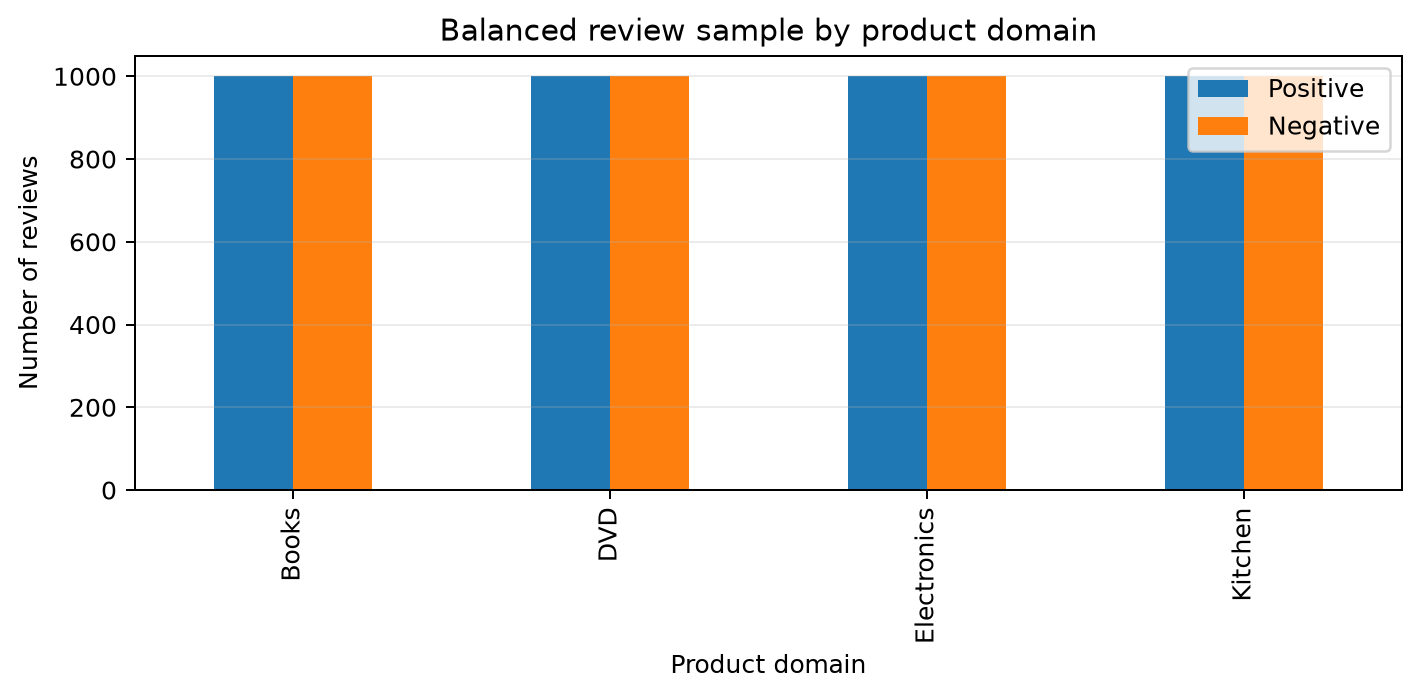

top_source_features.png


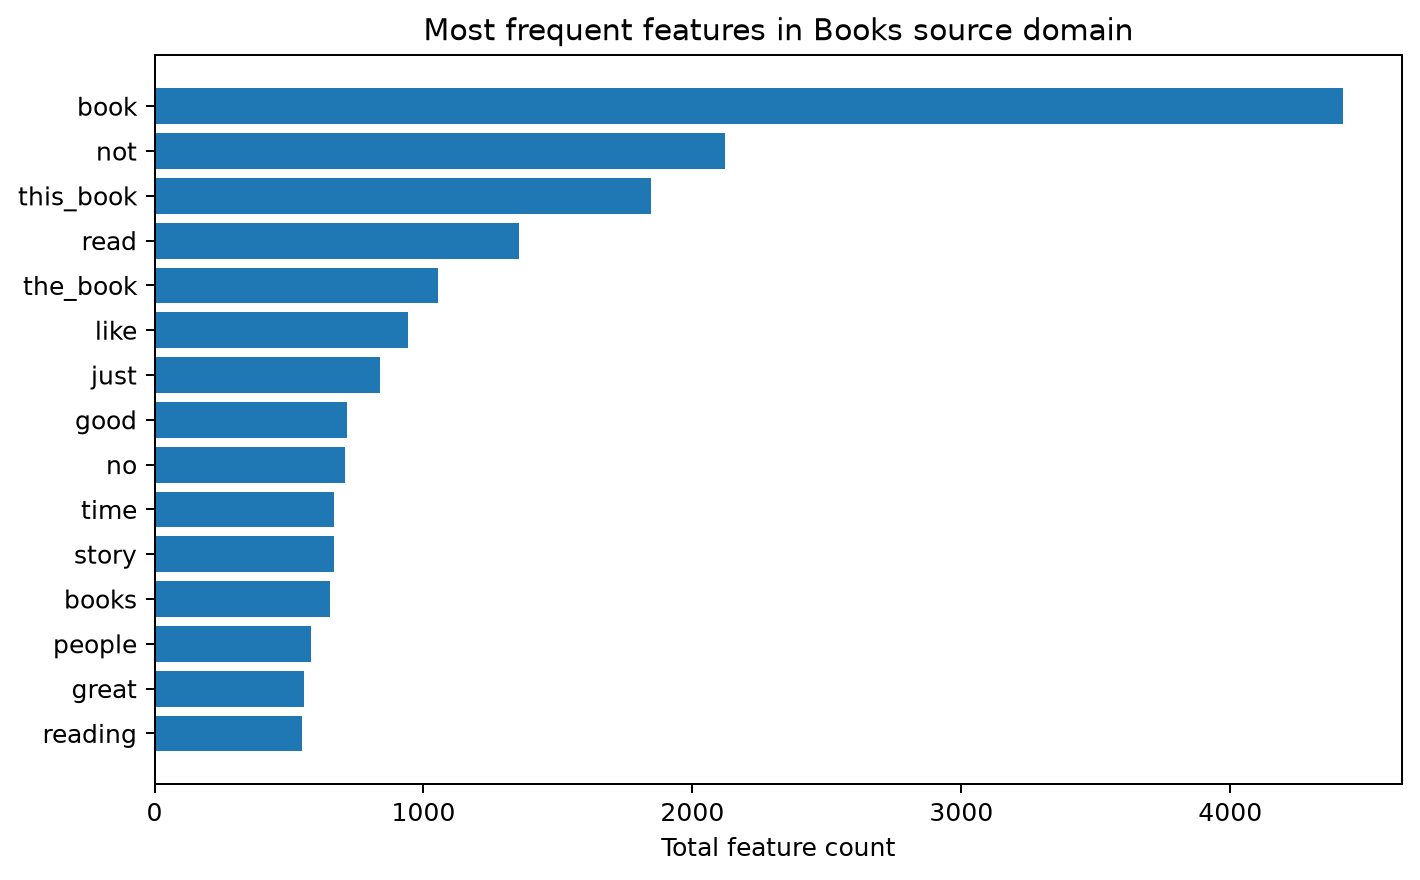

model_adaptation_gap.png


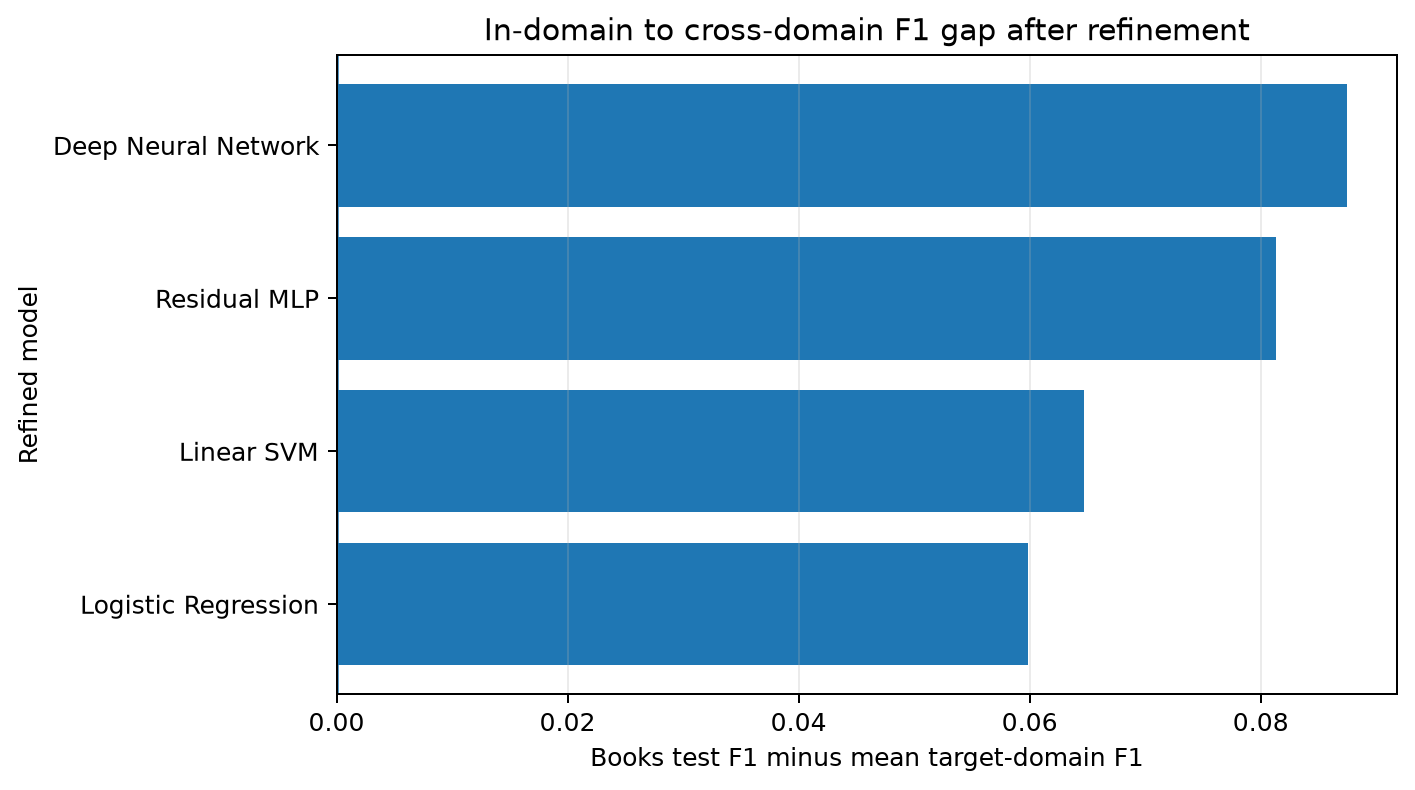

confusion_grid_electronics.png


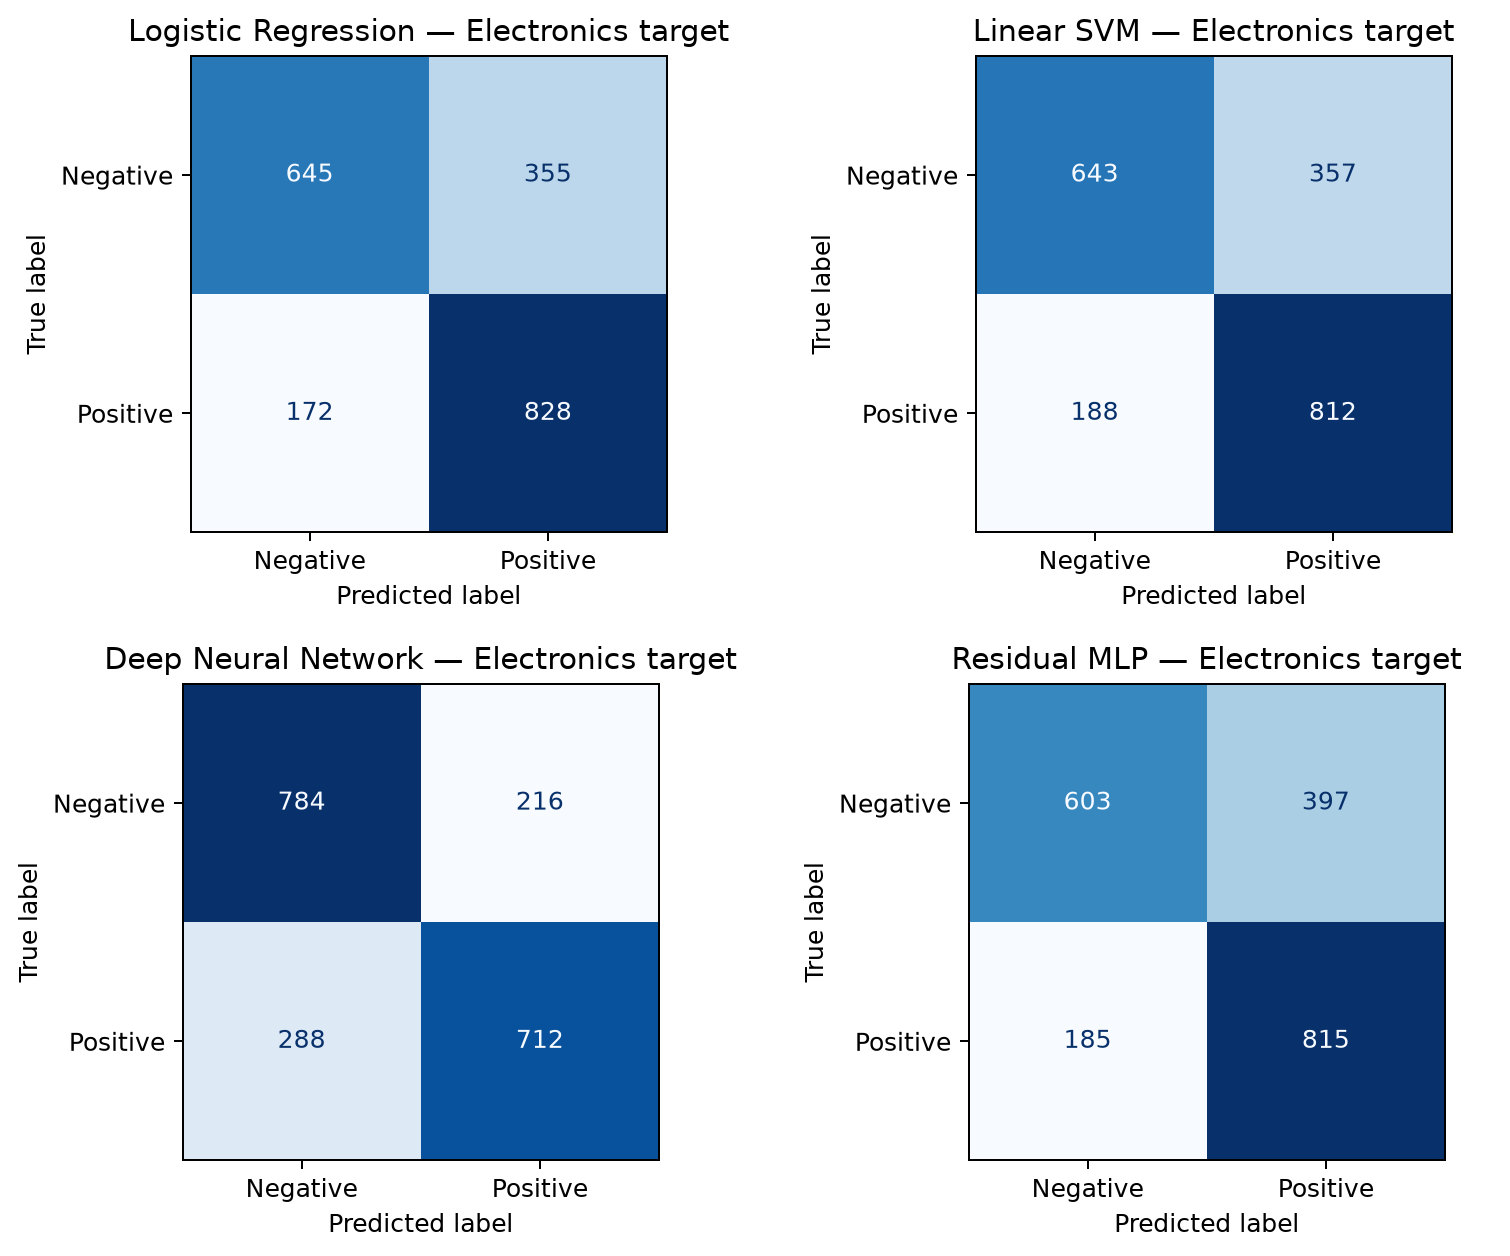

In [6]:
for filename in ['domain_class_balance.png', 'top_source_features.png', 'model_adaptation_gap.png', 'confusion_grid_electronics.png']:
    print(filename)
    display(Image(filename=str(RESULTS_DIR / 'figures' / filename)))

## 6. Saved outputs

The experiment creates dataset summaries, the unified evaluation table, the refinement log, confusion matrices and comparison figures. The report build step inserts the measured results and checks the 3,000-word maximum. No metric is manually entered.

In [7]:
print('Output files:')
for path in sorted(RESULTS_DIR.rglob('*')):
    if path.is_file(): print(path.relative_to(ROOT))

Output files:
results/.gitkeep
results/dataset_summary.csv
results/dataset_summary_full.csv
results/environment.json
results/experiment_metadata.json
results/figures/confusion_deep_neural_network_cross_domain_dvd.png
results/figures/confusion_deep_neural_network_cross_domain_electronics.png
results/figures/confusion_deep_neural_network_cross_domain_kitchen.png
results/figures/confusion_deep_neural_network_in_domain.png
results/figures/confusion_grid_electronics.png
results/figures/confusion_linear_svm_cross_domain_dvd.png
results/figures/confusion_linear_svm_cross_domain_electronics.png
results/figures/confusion_linear_svm_cross_domain_kitchen.png
results/figures/confusion_linear_svm_in_domain.png
results/figures/confusion_logistic_regression_cross_domain_dvd.png
results/figures/confusion_logistic_regression_cross_domain_electronics.png
results/figures/confusion_logistic_regression_cross_domain_kitchen.png
results/figures/confusion_logistic_regression_in_domain.png
results/figures/conf